# Predicción de deserción y éxito académico (UCI 697) — EDA, selección de variables, modelos y Optuna

**Integrantes y aportes** (completar; el enunciado pide indicar qué hizo cada uno):

- Integrante 1: ...
- Integrante 2: ...
- Integrante 3: ...
- Integrante 4: ...

**Uso de IA en el código** (completar con lo que realmente hicieron): el enunciado solo permite usar IA cuando se está atascado en algo específico y exige dejar el prompt como comentario. Si se usó, pegar aquí el prompt y a qué parte del código corresponde.

> `# PROMPT usado: ...`

---

**Qué cambió respecto a la versión anterior**

1. La columna objetivo (`Target`) ya **no entra a `X`**.
2. Se **separa primero** en entrenamiento y prueba. El escalado, la codificación, la selección de variables y el balanceo se ajustan **solo con entrenamiento** (dentro de un `Pipeline`, así también quedan dentro de la validación cruzada).
3. Los outliers **no se eliminan** del dataset completo: se detectan, se documentan y se decide (ver sección 2.3).
4. Se incluyen `Mother's occupation` y `Father's occupation`, que antes quedaban fuera de las listas.
5. Se agregan selección de variables, modelos propuestos (KNN y MLP), optimización con Optuna y la tabla comparativa final.

In [ ]:
!pip install -q optuna imbalanced-learn

In [ ]:
import warnings, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42

# Cambiar la URL si renombran el repositorio o el archivo
URL = "https://raw.githubusercontent.com/20232405-cloud/Estimaci-n-de-los-niveles-de-obesidad-/refs/heads/main/data.csv"

## 1. Carga de datos y definición de columnas

In [ ]:
df = pd.read_csv(URL, sep=";")

# Limpieza de nombres: quita espacios/tabulaciones y decodifica restos de HTML (&quot;, &#39;)
df.columns = [html.unescape(c).strip() for c in df.columns]
print(df.shape)   # esperado: (4424, 37)
df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
TARGET = "Target"

# Variables 0/1 (ya vienen codificadas; no necesitan encoder)
binarias = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
            "Tuition fees up to date", "Gender", "Scholarship holder", "International"]

# Variables categóricas nominales (códigos sin orden: el número NO significa "más" o "menos")
nominales = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

# Variables numéricas
numericas = ["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment",
             "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
             "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
             "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
             "Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)",
             "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
             "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)",
             "Unemployment rate", "Inflation rate", "GDP"]

# Comprobación: ninguna columna debe quedar fuera ni sobrar (así no se pierde nada en silencio)
definidas = set(binarias + nominales + numericas + [TARGET])
print("Columnas del CSV que no están en mis listas:", set(df.columns) - definidas)
print("Columnas de mis listas que no están en el CSV:", definidas - set(df.columns))
assert definidas == set(df.columns), "Revisar los nombres de columnas"

Columnas del CSV que no están en mis listas: set()
Columnas de mis listas que no están en el CSV: set()


## 2. Análisis exploratorio (EDA)

*Aquí pueden pegar sus gráficos adicionales del EDA anterior (univariante, demográficas, etc.). Abajo van los mínimos que necesita el reporte.*

### 2.1 Variable objetivo

          Cantidad  Porcentaje
Target                        
Graduate      2209       49.93
Dropout       1421       32.12
Enrolled       794       17.95


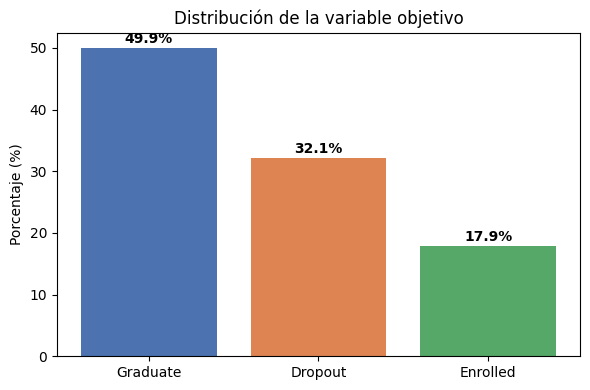

In [ ]:
dist = df[TARGET].value_counts()
pct = dist / len(df) * 100
print(pd.DataFrame({"Cantidad": dist, "Porcentaje": pct.round(2)}))

plt.figure(figsize=(6, 4))
plt.bar(pct.index, pct.values, color=["#4c72b0", "#dd8452", "#55a868"])
for i, v in enumerate(pct.values):
    plt.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")
plt.ylabel("Porcentaje (%)"); plt.title("Distribución de la variable objetivo")
plt.tight_layout(); plt.show()

**Interpretación (escribir con sus palabras):** ¿hay desbalance? ¿qué clase es la minoritaria y por qué importa?

### 2.2 Valores faltantes y duplicados

In [ ]:
print("Valores nulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

# Si hubiera duplicados exactos se eliminan (antes de separar los datos)
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Nuevo tamaño:", df.shape)

Valores nulos totales: 0
Filas duplicadas: 0


### 2.3 Outliers (método IQR)

Se **detectan y se documentan**, pero **no se eliminan**. Motivos para justificar en el reporte (editar si cambian de decisión):

- Eliminar las filas con un outlier en *cualquier* variable numérica quita muchos estudiantes. Revisen la columna "Porcentaje" de la tabla.
- Son datos académicos: valores como pocas unidades curriculares aprobadas o edades altas son reales y pueden ser justamente señal de deserción.
- Si se eliminara algo, debería hacerse **solo en el conjunto de entrenamiento**, nunca en el de prueba.

,Variable,Límite inferior,Límite superior,Outliers,Porcentaje
0,Curricular units 2nd sem (grade),6.87,17.21,877,19.82
1,Curricular units 1st sem (grade),7.40,17.00,726,16.41
2,Curricular units 1st sem (credited),0.00,0.00,577,13.04
3,Application order,-0.50,3.50,541,12.23
4,Curricular units 2nd sem (credited),0.00,0.00,530,11.98
5,Age at enrollment,10.00,34.00,441,9.97
6,Curricular units 1st sem (enrolled),2.00,10.00,424,9.58
7,Curricular units 2nd sem (enrolled),2.00,10.00,369,8.34
8,Curricular units 1st sem (without evaluations),0.00,0.00,294,6.65
9,Curricular units 2nd sem (without evaluations),0.00,0.00,282,6.37


Filas con al menos un outlier: 2422 de 4424 (54.7%)


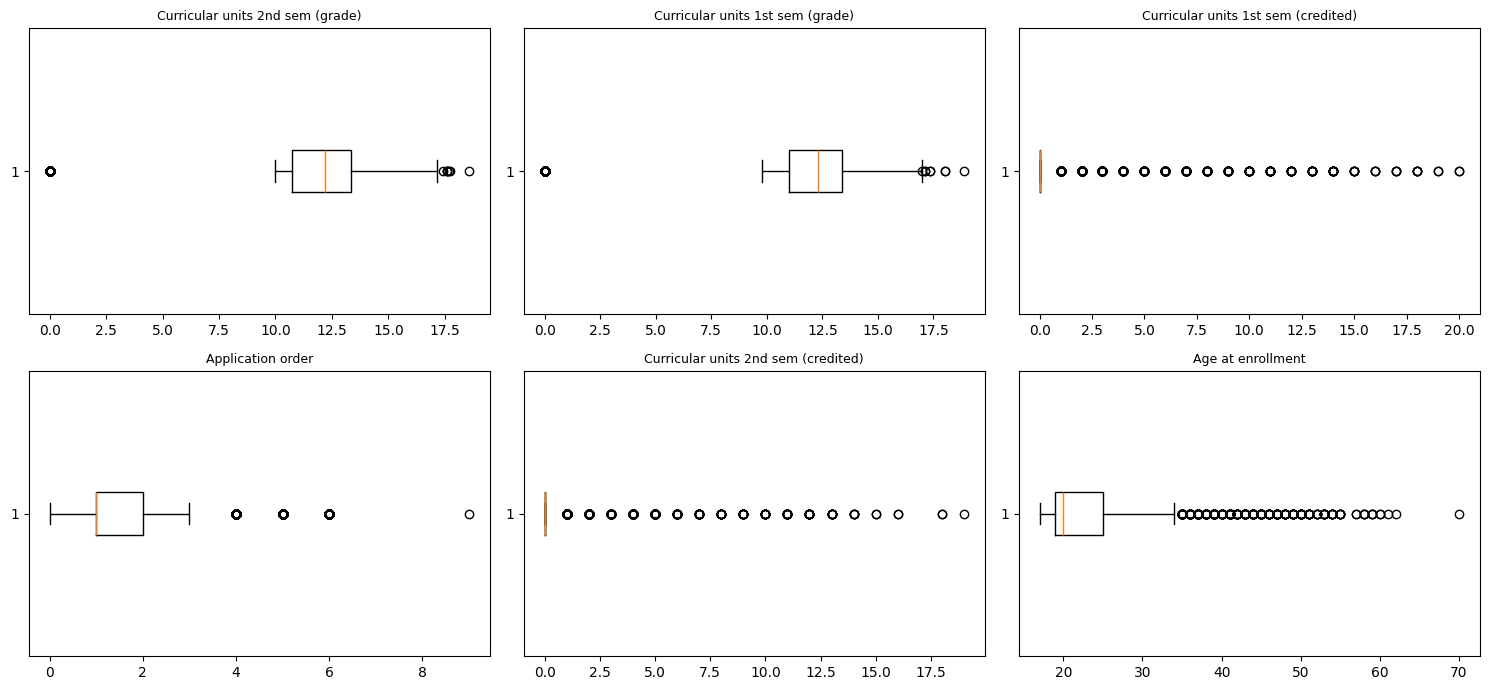

In [ ]:
def resumen_outliers_iqr(data, variables):
    filas = []
    for v in variables:
        q1, q3 = data[v].quantile(0.25), data[v].quantile(0.75)
        iqr = q3 - q1
        inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((data[v] < inf) | (data[v] > sup)).sum())
        filas.append({"Variable": v, "Límite inferior": round(inf, 2), "Límite superior": round(sup, 2),
                      "Outliers": n, "Porcentaje": round(n / len(data) * 100, 2)})
    return pd.DataFrame(filas).sort_values("Outliers", ascending=False).reset_index(drop=True)

tabla_outliers = resumen_outliers_iqr(df, numericas)
display(tabla_outliers)

# Filas que se perderían si se eliminara cualquier outlier (para justificar la decisión)
mask = pd.Series(False, index=df.index)
for v in numericas:
    q1, q3 = df[v].quantile(0.25), df[v].quantile(0.75)
    iqr = q3 - q1
    mask |= (df[v] < q1 - 1.5 * iqr) | (df[v] > q3 + 1.5 * iqr)
print(f"Filas con al menos un outlier: {int(mask.sum())} de {len(df)} ({mask.mean()*100:.1f}%)")

top = tabla_outliers.head(6)["Variable"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, v in zip(axes.ravel(), top):
    ax.boxplot(df[v], vert=False); ax.set_title(v, fontsize=9)
plt.tight_layout(); plt.show()

**Interpretación (escribir con sus palabras):** ¿qué variables tienen más outliers y qué decisión toman?

### 2.4 Correlación entre variables numéricas

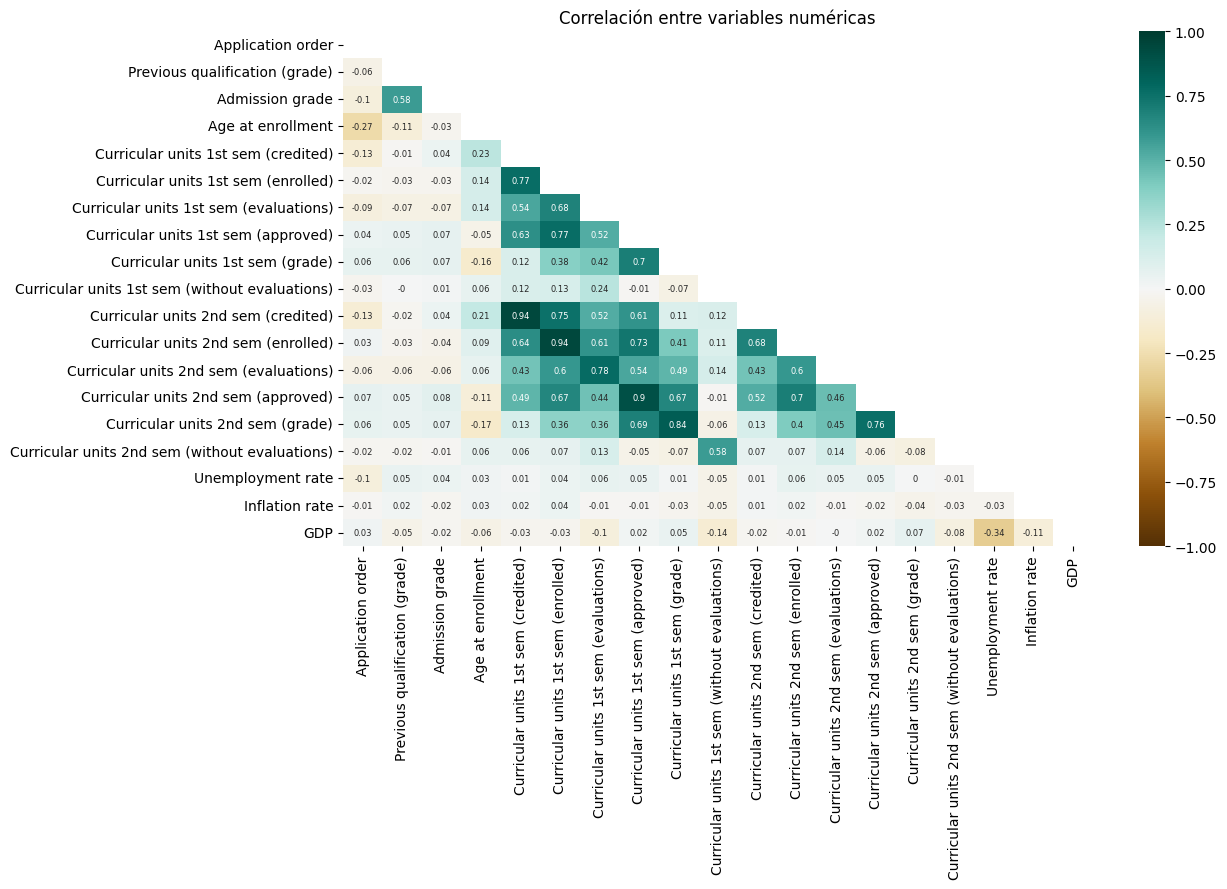

In [ ]:
import seaborn as sns
corr_total = df[numericas].corr()
plt.figure(figsize=(13, 9))
sns.heatmap(corr_total.round(2), mask=np.triu(np.ones_like(corr_total, dtype=bool)),
            cmap="BrBG", vmin=-1, vmax=1, annot=True, annot_kws={"size": 6})
plt.title("Correlación entre variables numéricas"); plt.tight_layout(); plt.show()

## 3. Separación en entrenamiento y prueba

Se hace **antes** de cualquier ajuste de escalado, codificación, selección o balanceo. Se usa `stratify` para mantener la proporción de clases. La validación se hace con **validación cruzada sobre el entrenamiento** (por eso ya no hace falta `X_valid`); el conjunto de prueba se usa **una sola vez al final**.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import LabelEncoder

X = df.drop(columns=[TARGET])
assert TARGET not in X.columns          # el objetivo NO puede estar en X

le = LabelEncoder()
y = le.fit_transform(df[TARGET])        # clases ordenadas alfabéticamente
CLASES = list(le.classes_)
print("Clases:", dict(zip(range(len(CLASES)), CLASES)))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

Clases: {0: 'Dropout', 1: 'Enrolled', 2: 'Graduate'}
Entrenamiento: (3539, 36) | Prueba: (885, 36)


## 4. Selección de variables

Dos pasos, ambos usando **solo el conjunto de entrenamiento**:

1. **Filtro por correlación:** de cada par de variables numéricas con |correlación| > 0.90 se elimina una.
2. **Importancia de variables con Random Forest** (documentada abajo y aplicada dentro del `Pipeline` con `SelectFromModel`, para que se recalcule en cada fold de la validación cruzada).

In [ ]:
UMBRAL_CORR = 0.90

corr = X_train[numericas].corr().abs()
superior = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
a_eliminar = [c for c in superior.columns if (superior[c] > UMBRAL_CORR).any()]

pares = [(a, b, round(superior.loc[a, b], 3)) for a in superior.index for b in superior.columns
         if pd.notna(superior.loc[a, b]) and superior.loc[a, b] > UMBRAL_CORR]
print("Pares con correlación alta:")
for p in pares:
    print("  ", p)

print("\nVariables numéricas eliminadas por correlación:", a_eliminar)
numericas_sel = [c for c in numericas if c not in a_eliminar]
print("Numéricas que se conservan:", len(numericas_sel), "de", len(numericas))

Pares con correlación alta:
   ('Curricular units 1st sem (credited)', 'Curricular units 2nd sem (credited)', np.float64(0.948))
   ('Curricular units 1st sem (enrolled)', 'Curricular units 2nd sem (enrolled)', np.float64(0.943))
   ('Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)', np.float64(0.907))

Variables numéricas eliminadas por correlación: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (approved)']
Numéricas que se conservan: 16 de 19


Columnas tras codificar: 103


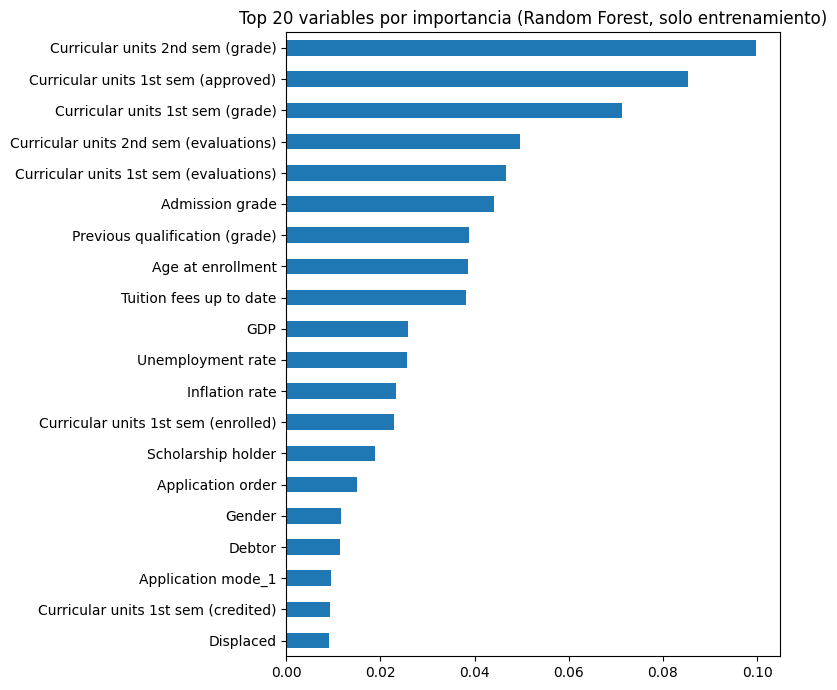

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

def crear_preprocesador():
    return ColumnTransformer([
        ("num", StandardScaler(), numericas_sel),
        # min_frequency agrupa categorías muy raras (<1%) para no generar cientos de columnas
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), nominales),
        ("bin", "passthrough", binarias),
    ])

# Importancia de variables (solo para documentar; ajustada solo con entrenamiento)
prep_doc = crear_preprocesador().fit(X_train)
Xtr_doc = prep_doc.transform(X_train)
nombres = [n.split("__", 1)[1] for n in prep_doc.get_feature_names_out()]
print("Columnas tras codificar:", Xtr_doc.shape[1])

rf_doc = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, class_weight="balanced")
rf_doc.fit(Xtr_doc, y_train)
importancias = pd.Series(rf_doc.feature_importances_, index=nombres).sort_values(ascending=False)

importancias.head(20).iloc[::-1].plot(kind="barh", figsize=(8, 7))
plt.title("Top 20 variables por importancia (Random Forest, solo entrenamiento)")
plt.tight_layout(); plt.show()

### Filtrado de variables más importantes mediante un umbral

Podemos usar `SelectFromModel` para establecer un umbral numérico específico o usar medidas estadísticas (como la media o mediana) para quedarnos únicamente con las características que realmente aportan valor predictivo.

In [ ]:
from sklearn.feature_selection import SelectFromModel

# Usamos el umbral dinámico 'mean' (la media de todas las importancias)
umbral_media = rf_doc.feature_importances_.mean()

# Creamos el selector utilizando el criterio 'mean'
selector = SelectFromModel(rf_doc, threshold='mean', prefit=True)

# Obtenemos las variables que superaron el umbral de la media
variables_seleccionadas = [nombres[i] for i in range(len(nombres)) if selector.get_support()[i]]
variables_descartadas = [nombres[i] for i in range(len(nombres)) if not selector.get_support()[i]]

print(f"--- FILTRADO CON UMBRAL DE LA MEDIA (Valor: {umbral_media:.5f}) ---")
print(f"Variables totales antes del filtro: {len(nombres)}")
print(f"Variables seleccionadas (por encima de la media): {len(variables_seleccionadas)}")
print(f"Variables descartadas: {len(variables_descartadas)}")

# Mostramos las variables seleccionadas ordenadas por importancia
importancias_seleccionadas = importancias[variables_seleccionadas].sort_values(ascending=False)
print("\nVariables seleccionadas para tu modelo e informe (ordenadas de mayor a menor importancia):")
display(importancias_seleccionadas)

--- FILTRADO CON UMBRAL DE LA MEDIA (Valor: 0.00971) ---
Variables totales antes del filtro: 103
Variables seleccionadas (por encima de la media): 17
Variables descartadas: 86

Variables seleccionadas para tu modelo e informe (ordenadas de mayor a menor importancia):


,0
Curricular units 2nd sem (grade),0.099879
Curricular units 1st sem (approved),0.085405
Curricular units 1st sem (grade),0.071405
Curricular units 2nd sem (evaluations),0.049636
Curricular units 1st sem (evaluations),0.046612
Admission grade,0.044135
Previous qualification (grade),0.038890
Age at enrollment,0.038558
Tuition fees up to date,0.038163
GDP,0.025862


### Análisis de Umbrales para el Informe

Vamos a calcular exactamente cuántas variables se seleccionan utilizando diferentes criterios de umbral para que puedas reportar estos datos en tu documento de análisis.

In [ ]:
# Calculamos la media y mediana de las importancias
importancia_media = rf_doc.feature_importances_.mean()
importancia_mediana = np.median(rf_doc.feature_importances_)

umbrales_prueba = {
    "Mediana (threshold='median')": importancia_mediana,
    "Media (threshold='mean')": importancia_media,
    "Fijo 0.5% (0.005)": 0.005,
    "Fijo 1.0% (0.010)": 0.010,
    "Fijo 1.5% (0.015)": 0.015,
    "Fijo 2.0% (0.020)": 0.020
}

resultados_umbrales = []
for nombre_umb, valor_umb in umbrales_prueba.items():
    # Contar cuántas variables superan el valor
    n_seleccionadas = int((importancias >= valor_umb).sum())
    porcentaje_conservado = (n_seleccionadas / len(nombres)) * 100
    resultados_umbrales.append({
        "Criterio de Umbral": nombre_umb,
        "Valor del Umbral": round(valor_umb, 5),
        "Variables Seleccionadas": n_seleccionadas,
        "% de Variables Conservadas": round(porcentaje_conservado, 1)
    })

df_umbrales = pd.DataFrame(resultados_umbrales)
display(df_umbrales)

,Criterio de Umbral,Valor del Umbral,Variables Seleccionadas,% de Variables Conservadas
0,Mediana (threshold='median'),0.00412,52,50.5
1,Media (threshold='mean'),0.00971,17,16.5
2,Fijo 0.5% (0.005),0.00500,44,42.7
3,Fijo 1.0% (0.010),0.01000,17,16.5
4,Fijo 1.5% (0.015),0.01500,15,14.6
5,Fijo 2.0% (0.020),0.02000,13,12.6


**Interpretación (escribir con sus palabras):** ¿qué variables resultan más importantes? ¿tiene sentido que sean del 1.er/2.º semestre? ¿qué implica eso para una predicción *temprana*?

## 5. Pipeline: preprocesamiento + selección + balanceo + modelo

Todo va dentro de un `Pipeline` de `imblearn`. Así, en cada fold de la validación cruzada, el escalado, la codificación, la selección y el balanceo se ajustan solo con los datos de entrenamiento de ese fold (sin filtrar información del fold de validación).

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek
from sklearn.feature_selection import SelectFromModel

def crear_pipeline(clf, sampler=None, seleccion=True):
    pasos = [("prep", crear_preprocesador())]
    if seleccion:
        pasos.append(("sel", SelectFromModel(
            RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, class_weight="balanced"),
            threshold="mean"))) # Modificado para usar la media de importancia
    if sampler is not None:
        pasos.append(("bal", sampler))
    pasos.append(("clf", clf))
    return Pipeline(pasos)

def cv_f1(pipe, cv=cv5):
    r = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    return r.mean(), r.std()

### 5.1 ¿Qué técnica de balanceo conviene? (Random Forest, validación cruzada sobre entrenamiento)

In [ ]:
samplers = {
    "Sin balanceo": lambda: None,
    "SMOTE":        lambda: SMOTE(random_state=SEED),
    "SMOTE+Tomek":  lambda: SMOTETomek(random_state=SEED),
    "ADASYN":       lambda: ADASYN(random_state=SEED),
}

filas = []
for nombre, fabrica in samplers.items():
    media, desv = cv_f1(crear_pipeline(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                                       sampler=fabrica()))
    filas.append({"Balanceo": nombre, "F1 macro (CV)": round(media, 4), "Desv.": round(desv, 4)})
tabla_balanceo = pd.DataFrame(filas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)
display(tabla_balanceo)

SAMPLER_ELEGIDO = tabla_balanceo.loc[0, "Balanceo"]
print("Técnica elegida:", SAMPLER_ELEGIDO)
nuevo_sampler = samplers[SAMPLER_ELEGIDO]

,Balanceo,F1 macro (CV),Desv.
0,SMOTE+Tomek,0.6960,0.0200
1,SMOTE,0.6913,0.0109
2,ADASYN,0.6814,0.0140
3,Sin balanceo,0.6671,0.0194


Técnica elegida: SMOTE+Tomek


**Interpretación (escribir con sus palabras):** ¿mejora el balanceo? ¿en qué clase? (la diferencia puede ser pequeña; comentarlo con honestidad).

### 5.2 ¿Ayuda la selección de variables? (Random Forest con y sin `SelectFromModel`)

In [ ]:
filas = []
for etiqueta, usar in [("Sin selección", False), ("Con selección (media de importancia)", True)]:
    pipe = crear_pipeline(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                          sampler=nuevo_sampler(), seleccion=usar)
    media, desv = cv_f1(pipe)
    filas.append({"Configuración": etiqueta, "F1 macro (CV)": round(media, 4), "Desv.": round(desv, 4)})
display(pd.DataFrame(filas))

# Cuántas columnas se conservan al ajustar con todo el entrenamiento
pipe_tmp = crear_pipeline(RandomForestClassifier(n_estimators=50, random_state=SEED), sampler=None).fit(X_train, y_train)
n_antes = pipe_tmp.named_steps["prep"].transform(X_train).shape[1]
n_despues = int(pipe_tmp.named_steps["sel"].get_support().sum())
print(f"Columnas tras codificar: {n_antes} -> tras selección (media): {n_despues}")

,Configuración,F1 macro (CV),Desv.
0,Sin selección,0.6956,0.0231
1,Con selección (media de importancia),0.6960,0.0200


Columnas tras codificar: 103 -> tras selección (media): 18


**Interpretación (escribir con sus palabras):** ¿se mantiene el rendimiento con menos variables? ¿qué ganan (simplicidad, menor sobreajuste)?

## 6. Modelos


- **Métodos propuestos** (no usados por los autores, a confirmar): **KNN** y **MLP (red neuronal)**. Justificar en el reporte por qué se eligieron (KNN: método basado en distancias, sensible a la escala y al ruido; MLP: puede capturar interacciones no lineales entre variables académicas y socioeconómicas).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, classification_report

resultados = []     # una fila por modelo (tabla final)
predicciones = {}   # para matrices de confusión

def registrar(nombre, origen, pipe):
    """Ajusta con TODO el entrenamiento y evalúa UNA vez en prueba."""
    f1_cv, _ = cv_f1(pipe)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fila = {
        "Modelo": nombre, "Origen": origen,
        "F1 macro (CV)": round(f1_cv, 4),
        "Accuracy (prueba)": round(accuracy_score(y_test, pred), 4),
        "F1 macro (prueba)": round(f1_score(y_test, pred, average="macro"), 4),
        "Recall macro (prueba)": round(recall_score(y_test, pred, average="macro"), 4),
    }
    rec_clase = recall_score(y_test, pred, average=None)
    for c, r in zip(CLASES, rec_clase):
        fila[f"Recall {c}"] = round(r, 4)
    resultados.append(fila)
    predicciones[nombre] = pred
    return pipe

# --- Referencia: métodos de los autores
registrar("Regresión logística", "Autores", crear_pipeline(LogisticRegression(max_iter=2000, random_state=SEED), sampler=nuevo_sampler()))
registrar("Árbol de decisión",   "Autores", crear_pipeline(DecisionTreeClassifier(max_depth=6, random_state=SEED), sampler=nuevo_sampler()))
registrar("Random Forest",       "Autores", crear_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), sampler=nuevo_sampler()))

# --- Propuestos SIN ajustar (para medir cuánto aporta Optuna)
registrar("KNN (sin ajustar)", "Propuesto", crear_pipeline(KNeighborsClassifier(), sampler=nuevo_sampler()))
registrar("MLP (sin ajustar)", "Propuesto", crear_pipeline(
    MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, early_stopping=True, random_state=SEED), sampler=nuevo_sampler()))

display(pd.DataFrame(resultados))

,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),Recall Dropout,Recall Enrolled,Recall Graduate
0,Regresión logística,Autores,0.6870,0.7153,0.6814,0.6954,0.6585,0.6541,0.7738
1,Árbol de decisión,Autores,0.6555,0.7017,0.6646,0.6783,0.6021,0.6478,0.7851
2,Random Forest,Autores,0.6966,0.7277,0.6714,0.6703,0.7042,0.4717,0.8348
3,KNN (sin ajustar),Propuesto,0.5922,0.6045,0.5768,0.5925,0.5951,0.5535,0.6290
4,MLP (sin ajustar),Propuesto,0.6787,0.7051,0.6650,0.6749,0.7007,0.5660,0.7579


## 7. Optimización de hiperparámetros con Optuna (estrategia a)

Optuna busca la mejor combinación de hiperparámetros maximizando el **F1 macro en validación cruzada (3 folds) sobre el entrenamiento**. El conjunto de prueba no interviene. Se optimizan los dos modelos propuestos.

> `N_TRIALS = 30` tarda varios minutos en Colab. Pueden bajarlo para probar y subirlo para la versión final.

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 30

def optimizar(sugerir, construir, n_trials=N_TRIALS):
    def objetivo(trial):
        params = sugerir(trial)
        pipe = construir(params)
        return cross_val_score(pipe, X_train, y_train, cv=cv3, scoring="f1_macro", n_jobs=-1).mean()
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=n_trials)
    return estudio

def graficar_optuna(estudio, titulo):
    vals = estudio.trials_dataframe()["value"]
    plt.figure(figsize=(6, 3.5))
    plt.plot(vals, "o", alpha=0.5, label="cada prueba")
    plt.plot(vals.cummax(), "-", label="mejor hasta el momento")
    plt.xlabel("Prueba"); plt.ylabel("F1 macro (CV)"); plt.title(titulo); plt.legend()
    plt.tight_layout(); plt.show()

### 7.1 KNN

Mejor F1 macro (CV): 0.6377
Mejores hiperparámetros: {'n_neighbors': 32, 'weights': 'distance', 'p': 1}


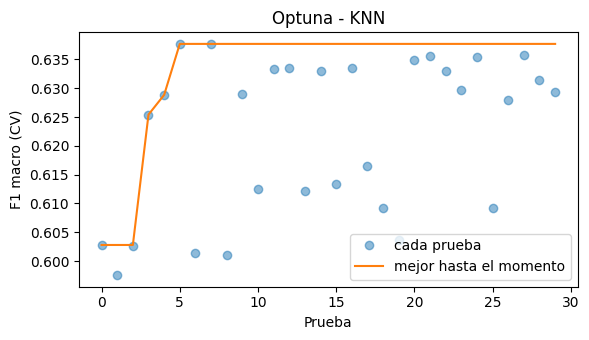

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Application order',
                                                   'Previous qualification '
                                                   '(grade)',
                                                   'Admission grade',
                                                   'Age at enrollment',
                                                   'Curricular units 1st sem '
                                                   '(credited)',
                                                   'Curricular units 1st sem '
                                                   '(enrolled)',
                                                   'Curricular units 1st sem '
                                                   '(evaluations)',
                                                   'Curricular units 1st sem '
                                                   '(approved)',
                                                   'Curricular units 1st sem '
                                                   '(grade)',
                                                   'C...
                                                   'Displaced',
                                                   'Educational special needs',
                                                   'Debtor',
                                                   'Tuition fees up to date',
                                                   'Gender',
                                                   'Scholarship holder',
                                                   'International'])])),
                ('sel',
                 SelectFromModel(estimator=RandomForestClassifier(class_weight='balanced',
                                                                  n_jobs=-1,
                                                                  random_state=42),
                                 threshold='mean')),
                ('bal', SMOTETomek(random_state=42)),
                ('clf',
                 KNeighborsClassifier(n_neighbors=32, p=1,
                                      weights='distance'))])

In [ ]:
def sugerir_knn(trial):
    return {
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 51),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "p": trial.suggest_int("p", 1, 2),          # 1 = Manhattan, 2 = Euclídea
    }

def construir_knn(params):
    return crear_pipeline(KNeighborsClassifier(**params), sampler=nuevo_sampler())

estudio_knn = optimizar(sugerir_knn, construir_knn)
print("Mejor F1 macro (CV):", round(estudio_knn.best_value, 4))
print("Mejores hiperparámetros:", estudio_knn.best_params)
graficar_optuna(estudio_knn, "Optuna - KNN")

registrar("KNN (Optuna)", "Propuesto", construir_knn(estudio_knn.best_params))

### 7.2 Red neuronal MLP

Mejor F1 macro (CV): 0.6903
Mejores hiperparámetros: {'n_capas': 1, 'unidades_0': 64, 'activation': 'tanh', 'alpha': 0.00019098782750915383, 'learning_rate_init': 0.0008547778345600965, 'batch_size': 32}


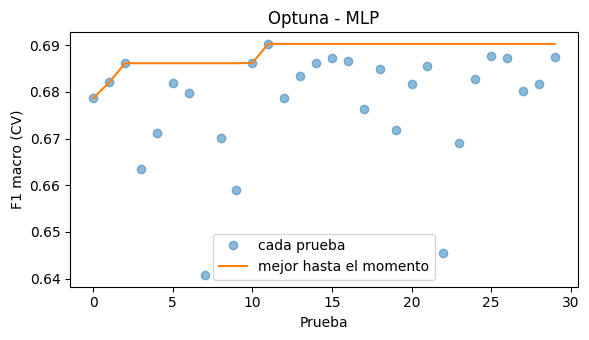


Importancia de cada hiperparámetro: {'learning_rate_init': 0.627, 'alpha': 0.193, 'unidades_0': 0.103, 'n_capas': 0.042, 'activation': 0.021, 'batch_size': 0.015, 'unidades_1': 0.0, 'unidades_2': 0.0}


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Application order',
                                                   'Previous qualification '
                                                   '(grade)',
                                                   'Admission grade',
                                                   'Age at enrollment',
                                                   'Curricular units 1st sem '
                                                   '(credited)',
                                                   'Curricular units 1st sem '
                                                   '(enrolled)',
                                                   'Curricular units 1st sem '
                                                   '(evaluations)',
                                                   'Curricular units 1st sem '
                                                   '(approved)',
                                                   'Curricular units 1st sem '
                                                   '(grade)',
                                                   'C...
                 SelectFromModel(estimator=RandomForestClassifier(class_weight='balanced',
                                                                  n_jobs=-1,
                                                                  random_state=42),
                                 threshold='mean')),
                ('bal', SMOTETomek(random_state=42)),
                ('clf',
                 MLPClassifier(activation='tanh', alpha=0.00019098782750915383,
                               batch_size=32, early_stopping=True,
                               hidden_layer_sizes=(64,),
                               learning_rate_init=0.0008547778345600965,
                               max_iter=300, random_state=42))])

In [ ]:
def sugerir_mlp(trial):
    n_capas = trial.suggest_int("n_capas", 1, 3)
    unidades = tuple(trial.suggest_int(f"unidades_{i}", 16, 128, step=16) for i in range(n_capas))
    return {
        "hidden_layer_sizes": unidades,
        "activation": trial.suggest_categorical("activation", ["relu", "tanh"]),
        "alpha": trial.suggest_float("alpha", 1e-5, 1e-1, log=True),                  # regularización L2
        "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128]),
    }

def construir_mlp(params):
    return crear_pipeline(
        MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=10, random_state=SEED, **params),
        sampler=nuevo_sampler())

estudio_mlp = optimizar(sugerir_mlp, construir_mlp)
print("Mejor F1 macro (CV):", round(estudio_mlp.best_value, 4))
print("Mejores hiperparámetros:", estudio_mlp.best_params)
graficar_optuna(estudio_mlp, "Optuna - MLP")

try:
    imp_hp = optuna.importance.get_param_importances(estudio_mlp)
    print("\nImportancia de cada hiperparámetro:", {k: round(v, 3) for k, v in imp_hp.items()})
except Exception as e:
    print("No se pudo calcular la importancia de hiperparámetros (pocas pruebas):", e)

# best_params incluye las claves auxiliares (n_capas, unidades_i); se reconstruye la arquitectura
bp = estudio_mlp.best_params
mejores_mlp = {
    "hidden_layer_sizes": tuple(bp[f"unidades_{i}"] for i in range(bp["n_capas"])),
    "activation": bp["activation"], "alpha": bp["alpha"],
    "learning_rate_init": bp["learning_rate_init"], "batch_size": bp["batch_size"],
}
registrar("MLP (Optuna)", "Propuesto", construir_mlp(mejores_mlp))

**Interpretación (escribir con sus palabras):** ¿cuánto mejoró cada modelo con Optuna respecto a los hiperparámetros por defecto? ¿qué hiperparámetros pesaron más?

## 8. Comparación final de todos los modelos (conjunto de prueba)

,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),Recall Dropout,Recall Enrolled,Recall Graduate
0,Regresión logística,Autores,0.6870,0.7153,0.6814,0.6954,0.6585,0.6541,0.7738
1,Random Forest,Autores,0.6966,0.7277,0.6714,0.6703,0.7042,0.4717,0.8348
2,MLP (Optuna),Propuesto,0.6814,0.7085,0.6672,0.6761,0.7148,0.5535,0.7602
3,MLP (Optuna),Propuesto,0.6814,0.7085,0.6672,0.6761,0.7148,0.5535,0.7602
4,MLP (sin ajustar),Propuesto,0.6787,0.7051,0.6650,0.6749,0.7007,0.5660,0.7579
5,Árbol de decisión,Autores,0.6555,0.7017,0.6646,0.6783,0.6021,0.6478,0.7851
6,KNN (Optuna),Propuesto,0.6494,0.6667,0.6267,0.6370,0.5528,0.5912,0.7670
7,KNN (sin ajustar),Propuesto,0.5922,0.6045,0.5768,0.5925,0.5951,0.5535,0.6290


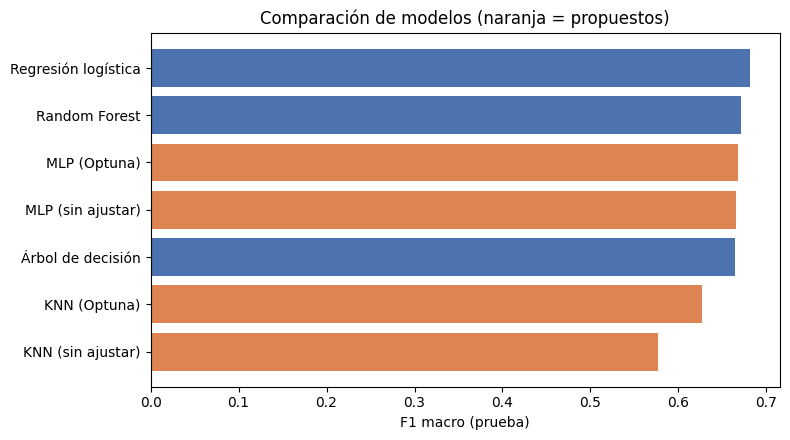

In [ ]:
tabla_final = pd.DataFrame(resultados).sort_values("F1 macro (prueba)", ascending=False).reset_index(drop=True)
display(tabla_final)
tabla_final.to_csv("resultados_estudiantes.csv", index=False)

plt.figure(figsize=(8, 4.5))
orden = tabla_final.iloc[::-1]
colores = ["#dd8452" if o == "Propuesto" else "#4c72b0" for o in orden["Origen"]]
plt.barh(orden["Modelo"], orden["F1 macro (prueba)"], color=colores)
plt.xlabel("F1 macro (prueba)"); plt.title("Comparación de modelos (naranja = propuestos)")
plt.tight_layout(); plt.show()

Mejor modelo por F1 macro en prueba: Regresión logística 

              precision    recall  f1-score   support

     Dropout       0.85      0.66      0.74       284
    Enrolled       0.39      0.65      0.49       159
    Graduate       0.86      0.77      0.81       442

    accuracy                           0.72       885
   macro avg       0.70      0.70      0.68       885
weighted avg       0.77      0.72      0.73       885



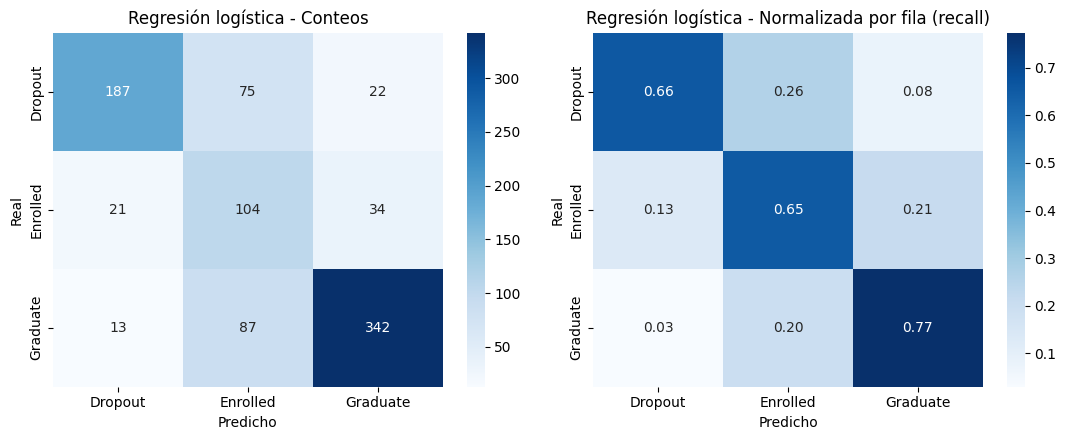

In [ ]:
mejor = tabla_final.loc[0, "Modelo"]
print("Mejor modelo por F1 macro en prueba:", mejor, "\n")
print(classification_report(y_test, predicciones[mejor], target_names=CLASES))

cm = confusion_matrix(y_test, predicciones[mejor])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, M, t, fmt in [(axes[0], cm, "Conteos", "d"), (axes[1], cm_norm, "Normalizada por fila (recall)", ".2f")]:
    sns.heatmap(M, annot=True, fmt=fmt, cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_title(f"{mejor} - {t}"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

=== MATRIZ DE CONFUSIÓN: MLP (Optuna) ===

              precision    recall  f1-score   support

     Dropout       0.77      0.71      0.74       284
    Enrolled       0.40      0.55      0.46       159
    Graduate       0.84      0.76      0.80       442

    accuracy                           0.71       885
   macro avg       0.67      0.68      0.67       885
weighted avg       0.74      0.71      0.72       885



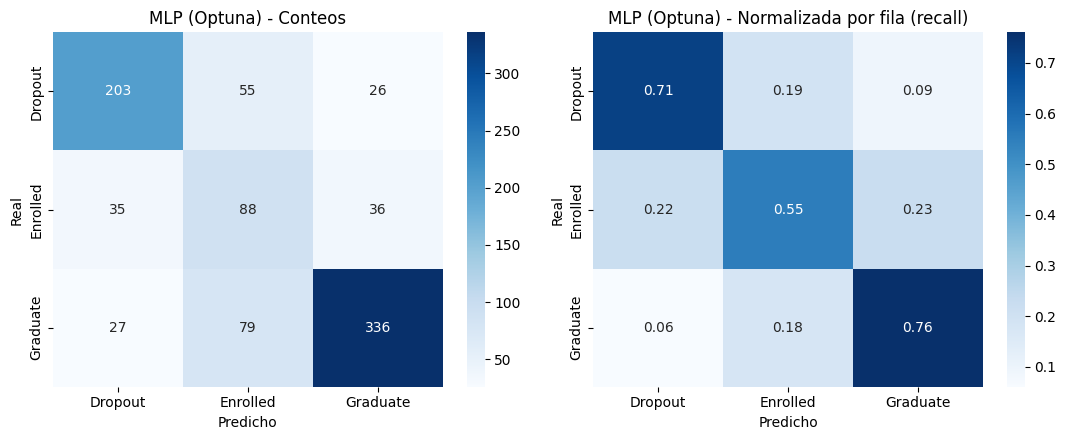



=== MATRIZ DE CONFUSIÓN: KNN (Optuna) ===

              precision    recall  f1-score   support

     Dropout       0.80      0.55      0.65       284
    Enrolled       0.35      0.59      0.44       159
    Graduate       0.81      0.77      0.79       442

    accuracy                           0.67       885
   macro avg       0.65      0.64      0.63       885
weighted avg       0.72      0.67      0.68       885



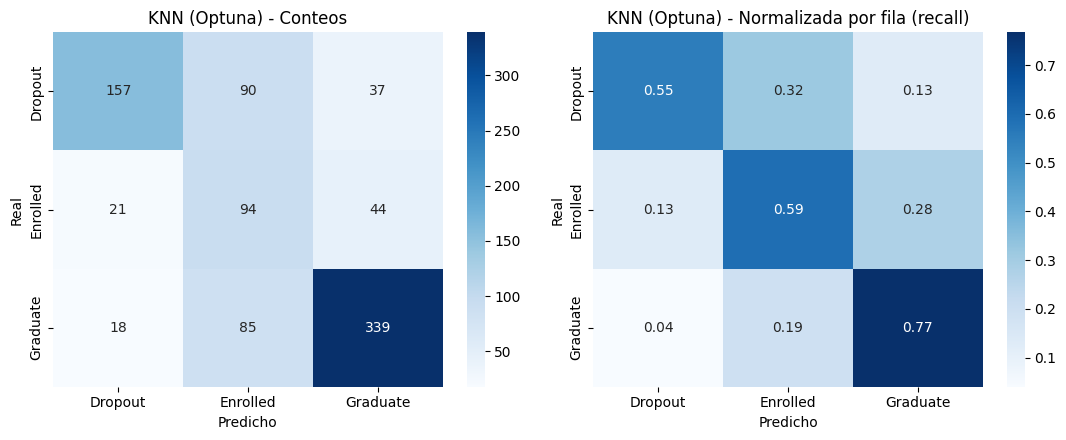

In [ ]:
modelos_a_graficar = ["MLP (Optuna)", "KNN (Optuna)"]

for nombre_modelo in modelos_a_graficar:
    if nombre_modelo in predicciones:
        print(f"=== MATRIZ DE CONFUSIÓN: {nombre_modelo} ===\n")
        print(classification_report(y_test, predicciones[nombre_modelo], target_names=CLASES))

        cm_mod = confusion_matrix(y_test, predicciones[nombre_modelo])
        cm_mod_norm = cm_mod / cm_mod.sum(axis=1, keepdims=True)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        # Gráfico 1: Conteos
        sns.heatmap(cm_mod, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=axes[0])
        axes[0].set_title(f"{nombre_modelo} - Conteos")
        axes[0].set_xlabel("Predicho")
        axes[0].set_ylabel("Real")

        # Gráfico 2: Normalizado
        sns.heatmap(cm_mod_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=axes[1])
        axes[1].set_title(f"{nombre_modelo} - Normalizada por fila (recall)")
        axes[1].set_xlabel("Predicho")
        axes[1].set_ylabel("Real")

        plt.tight_layout()
        plt.show()
        print("\n" + "="*50 + "\n")
    else:
        print(f"El modelo {nombre_modelo} no se encuentra en el diccionario de predicciones. Asegúrate de ejecutar todas las celdas del notebook.")

**Interpretación (escribir con sus palabras):** ¿qué modelo gana y por cuánto? ¿es una diferencia relevante o está dentro del ruido? ¿qué clase es la más difícil (casi siempre `Enrolled`) y por qué? ¿los modelos propuestos superan a los de los autores?

---

## Pendientes (fuera de este cuaderno)

- Repetir el flujo con el dataset de **obesidad** (el proyecto pide ambos).
- Confirmar en el paper original qué métodos usaron los autores.
- Reporte: estructura pedida, con redacción propia y la discusión ética y social.